In [1]:
import pandas as pd, os
p=r"C:\Users\deepa\Downloads\archive (2)\bank-additional-full.csv"
df=pd.read_csv(p, sep=';')
df.shape, df.head(), df.dtypes, df['y'].value_counts(normalize=True)

((41188, 21),
    age        job  marital    education  default housing loan    contact  \
 0   56  housemaid  married     basic.4y       no      no   no  telephone   
 1   57   services  married  high.school  unknown      no   no  telephone   
 2   37   services  married  high.school       no     yes   no  telephone   
 3   40     admin.  married     basic.6y       no      no   no  telephone   
 4   56   services  married  high.school       no      no  yes  telephone   
 
   month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
 0   may         mon  ...         1    999         0  nonexistent          1.1   
 1   may         mon  ...         1    999         0  nonexistent          1.1   
 2   may         mon  ...         1    999         0  nonexistent          1.1   
 3   may         mon  ...         1    999         0  nonexistent          1.1   
 4   may         mon  ...         1    999         0  nonexistent          1.1   
 
    cons.price.idx  cons.con

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [4]:
missing_values = df.isnull().sum()

print(missing_values)

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [5]:
print(df.isnull().sum()[df.isnull().sum() > 0])

Series([], dtype: int64)


In [6]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 12


In [7]:
print(df["y"].value_counts())

y
no     36548
yes     4640
Name: count, dtype: int64


In [8]:
print(df["y"].value_counts(normalize=True) * 100)

y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


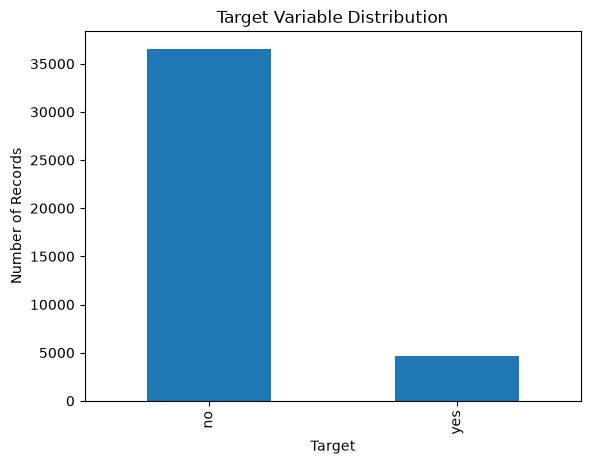

In [9]:
df["y"].value_counts().plot(kind="bar")

plt.title("Target Variable Distribution")
plt.xlabel("Target")
plt.ylabel("Number of Records")
plt.show()

In [10]:
df["y"] = df["y"].map({"no": 0, "yes": 1})

print(df["y"].value_counts())

y
0    36548
1     4640
Name: count, dtype: int64


In [11]:
X = df.drop("y", axis=1)
y = df["y"]

In [12]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (41188, 20)
Target shape: (41188,)


In [13]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (32950, 20)
Testing data: (8238, 20)


In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [16]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Models created successfully.")

Models created successfully.


In [17]:
results = []

trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )
    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    trained_models[name] = pipeline

    print("Accuracy:", accuracy)
    print("F1 Score:", f1)


Training: Logistic Regression
Accuracy: 0.9166059723233795
F1 Score: 0.5410821643286573

Training: Decision Tree
Accuracy: 0.894634620053411
F1 Score: 0.5282608695652173

Training: Random Forest
Accuracy: 0.9191551347414421
F1 Score: 0.573076923076923

Training: KNN
Accuracy: 0.9075018208302986
F1 Score: 0.5213567839195979

Training: SVM
Accuracy: 0.9153920854576354
F1 Score: 0.5287356321839081

Training: Gradient Boosting
Accuracy: 0.9217042971595047
F1 Score: 0.6093276801938219


In [18]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
5,Gradient Boosting,0.921704,0.695712,0.542026,0.609328
2,Random Forest,0.919155,0.707278,0.481681,0.573077
0,Logistic Regression,0.916606,0.711775,0.436422,0.541082
4,SVM,0.915392,0.709619,0.421336,0.528736
1,Decision Tree,0.894635,0.532895,0.523707,0.528261
3,KNN,0.907502,0.625000,0.447198,0.521357


In [19]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Gradient Boosting


In [20]:
y_pred_best = best_model.predict(X_test)

print("Classification Report")
print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=["No", "Yes"]
    )
)

Classification Report
              precision    recall  f1-score   support

          No       0.94      0.97      0.96      7310
         Yes       0.70      0.54      0.61       928

    accuracy                           0.92      8238
   macro avg       0.82      0.76      0.78      8238
weighted avg       0.92      0.92      0.92      8238



In [21]:
cm = confusion_matrix(
    y_test,
    y_pred_best
)

print(cm)

[[7090  220]
 [ 425  503]]


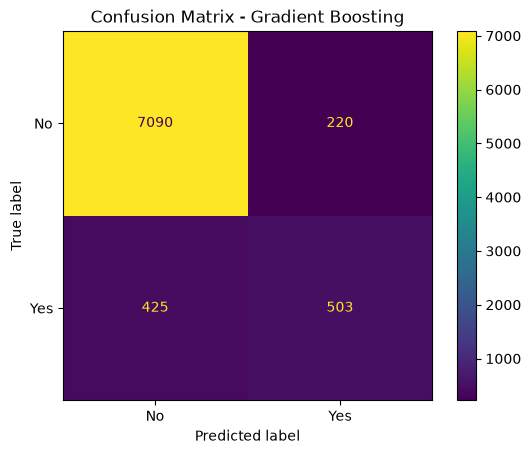

In [22]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot()

plt.title(
    "Confusion Matrix - " + best_model_name
)

plt.show()

In [23]:
sample = X_test.iloc[[0]]

prediction = best_model.predict(sample)[0]

if prediction == 1:
    print("Predicted Result: YES")
else:
    print("Predicted Result: NO")

Predicted Result: NO


In [24]:
import joblib

In [25]:
joblib.dump(
    best_model,
    "best_bank_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


In [26]:
loaded_model = joblib.load(
    "best_bank_model.pkl"
)

print("Model loaded successfully!")

Model loaded successfully!


In [27]:
loaded_prediction = loaded_model.predict(
    X_test.iloc[[0]]
)[0]

if loaded_prediction == 1:
    print("Loaded Model Prediction: YES")
else:
    print("Loaded Model Prediction: NO")

Loaded Model Prediction: NO


In [28]:
print("===================================")
print(" MACHINE LEARNING EXPERIMENT")
print("===================================")

print("Dataset Rows:", df.shape[0])
print("Dataset Columns:", df.shape[1])

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nBest Model:", best_model_name)

best_row = results_df.iloc[0]

print("Accuracy:", round(best_row["Accuracy"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1 Score:", round(best_row["F1 Score"], 4))

 MACHINE LEARNING EXPERIMENT
Dataset Rows: 41188
Dataset Columns: 21
Training Samples: 32950
Testing Samples: 8238

Best Model: Gradient Boosting
Accuracy: 0.9217
Precision: 0.6957
Recall: 0.542
F1 Score: 0.6093


In [29]:
y_pred_best = best_model.predict(X_test)

print("Classification Report")
print("=====================")

print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=["No", "Yes"]
    )
)

Classification Report
              precision    recall  f1-score   support

          No       0.94      0.97      0.96      7310
         Yes       0.70      0.54      0.61       928

    accuracy                           0.92      8238
   macro avg       0.82      0.76      0.78      8238
weighted avg       0.92      0.92      0.92      8238



Confusion Matrix:
[[7090  220]
 [ 425  503]]


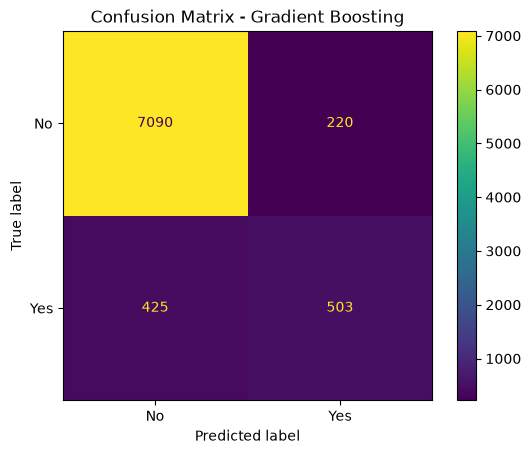

In [30]:
cm = confusion_matrix(y_test, y_pred_best)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot()
plt.title("Confusion Matrix - " + best_model_name)
plt.show()

In [31]:
import joblib

joblib.dump(best_model, "best_bank_marketing_model.pkl")

print("Best model saved successfully!")

Best model saved successfully!


In [32]:
loaded_model = joblib.load("best_bank_marketing_model.pkl")

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [33]:
print("===================================")
print(" MACHINE LEARNING EXPERIMENT")
print("===================================")

print("Dataset Rows:", df.shape[0])
print("Dataset Columns:", df.shape[1])

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nBest Model:", best_model_name)

best_row = results_df.iloc[0]

print("Accuracy :", round(best_row["Accuracy"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall   :", round(best_row["Recall"], 4))
print("F1 Score :", round(best_row["F1 Score"], 4))

print("\nModel saved as: best_bank_marketing_model.pkl")

 MACHINE LEARNING EXPERIMENT
Dataset Rows: 41188
Dataset Columns: 21
Training Samples: 32950
Testing Samples: 8238

Best Model: Gradient Boosting
Accuracy : 0.9217
Precision: 0.6957
Recall   : 0.542
F1 Score : 0.6093

Model saved as: best_bank_marketing_model.pkl


In [35]:
import os
print(os.getcwd())

C:\Users\deepa


In [36]:
import os
print(os.listdir())

['.anaconda', '.antigravity', '.aws', '.cache', '.conda', '.continuum', '.copilot', '.eclipse', '.gemini', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.kiro', '.m2', '.mamba', '.matplotlib', '.p2', '.pdfbox.cache', '.vscode', '.vscode-shared', 'anaconda3', 'AppData', 'Application Data', 'bank_feature_engineered_v3.csv', 'Bank_ML_Experiment.ipynb', 'bank_processed.csv', 'bank_processed_v2.csv', 'bank_raw_v1.csv', 'battery-report.html', 'best_bank_marketing_model.pkl', 'best_bank_model.pkl', 'Contacts', 'Cookies', 'Documents', 'Downloads', 'eclipse', 'eclipse-workspace', 'Favorites', 'kidney_disease.csv', 'Links', 'Local Settings', 'lostfound_db.mv.db', 'lostfound_db.trace.db', 'Maven', 'Maven_Tool', 'mlflow.db', 'mlflow_bank.db', 'mlruns', 'model_comparison_results.csv', 'MultiFunctionalityUtility.java', 'Music', 'My Documents', 'NetHood', 'node_modules', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf', 'NTUSER.

In [1]:
!git --version

git version 2.56.0.windows.2


In [2]:
!git init

Initialized empty Git repository in C:/Users/deepa/.git/


In [4]:
!rmdir /s /q .git